### Example 1: learning Lotka-Volterra with NODE

In [2]:
import torch
import torch.nn as nn
from torchdiffeq import odeint
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Define the Lotka-Volterra system
def lv(t, u):

    x, y = u  # u is a tensor of shape (batch_size, 2)

    # standard LV parameters (deterministic)
    a, b, c, d = 1.5, 1.0, 3.0, 1.0

    dxdt = a*x - b*x*y
    dydt = (-c)*y + d*x*y

    return torch.stack([dxdt, dydt]) 



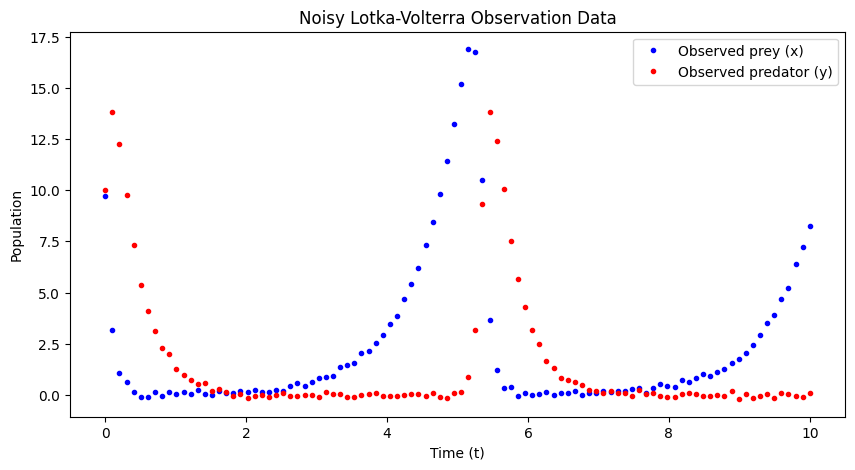

In [4]:
# Generate training data

# initial conditions of prey and predator populations
u0 = torch.tensor([10.0, 10.0])
# time span for training data
t_span = torch.linspace(0., 10., 100)

# generate data from the true system above
with torch.no_grad(): 
    true_data = odeint(lv, u0, t_span, method='dopri5') 

# add a small amount of Gaussian noise to simulate real-world data collection
noise = 0.1*torch.randn(true_data.shape)
obs_data = true_data + noise

plt.figure(figsize=(10,5))
plt.plot(t_span.numpy(), obs_data[:, 0].numpy(), 'b.', label='Observed prey (x)')
plt.plot(t_span.numpy(), obs_data[:, 1].numpy(), 'r.', label='Observed predator (y)')
plt.title("Noisy Lotka-Volterra Observation Data")
plt.xlabel("Time (t)")
plt.ylabel("Population")
plt.legend()
plt.show()

In [5]:
# Define the NODE components 

class ODEFunc(nn.Module):
    """
    The NN that learns the unknown derivative f(u, t).
    It's a simple 2-layer fully connected MLP.
    """

    def __init__(self):
        super(ODEFunc, self).__init__()
# so that child classes that may be using cooperative multiple inheritance will 
# call the correct next parent class function in the Method Resolution Order
        
        # 2 inputs (x, y) -> 128 hidden units -> 2 outputs (dx/dt, dy/dt)
        self.net = nn.Sequential(
            nn.Linear(2, 128),
            nn.Tanh(),
            nn.Linear(128, 2)
        )

    def forward(self, t, u):
        # passing the current state u through the network
        return self.net(u)


In [11]:
# Training loop

# initialize model components
func = ODEFunc()  # this is the f_theta (an NN)
optimizer = torch.optim.Adam(func.parameters(), lr = 1e-3)
loss_fn = nn.MSELoss()
epochs = 5000

# start training
for epoch in range(epochs):
    # reset optimizer
    optimizer.zero_grad()

    # solve the ODE using the current NN parameters
    # the initial condition is the first data point
    u0_train = obs_data[0]
    pred_data = odeint(func, u0_train, t_span)

    # calculate loss against observed data
    loss = loss_fn(pred_data, obs_data)

    # backprop via adjoint method (handled by odeint)
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{epochs}, Loss: {loss.item():.6f}")

print(f"Final loss: {loss.item():.6f}")

Epoch 0/5000, Loss: 82.669998
Epoch 50/5000, Loss: 19.112255
Epoch 100/5000, Loss: 16.625319
Epoch 150/5000, Loss: 14.813511
Epoch 200/5000, Loss: 13.695459
Epoch 250/5000, Loss: 12.991168
Epoch 300/5000, Loss: 12.513641
Epoch 350/5000, Loss: 12.168000
Epoch 400/5000, Loss: 11.900071
Epoch 450/5000, Loss: 11.670381
Epoch 500/5000, Loss: 11.439546
Epoch 550/5000, Loss: 11.178352
Epoch 600/5000, Loss: 10.903076
Epoch 650/5000, Loss: 10.646136
Epoch 700/5000, Loss: 10.418545
Epoch 750/5000, Loss: 10.218458
Epoch 800/5000, Loss: 10.037823
Epoch 850/5000, Loss: 9.829190
Epoch 900/5000, Loss: 8.980483
Epoch 950/5000, Loss: 7.707500
Epoch 1000/5000, Loss: 7.043644
Epoch 1050/5000, Loss: 6.497296
Epoch 1100/5000, Loss: 5.978302
Epoch 1150/5000, Loss: 5.507183
Epoch 1200/5000, Loss: 5.095376
Epoch 1250/5000, Loss: 4.741235
Epoch 1300/5000, Loss: 4.436621
Epoch 1350/5000, Loss: 4.170823
Epoch 1400/5000, Loss: 3.935251
Epoch 1450/5000, Loss: 3.724144
Epoch 1500/5000, Loss: 3.533633
Epoch 1550/500

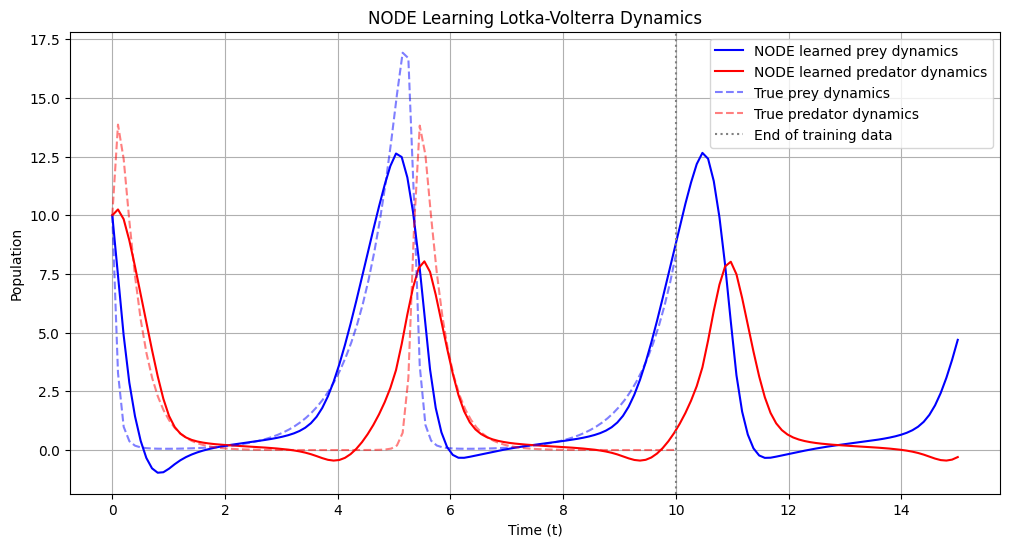

In [12]:
# Visualize result and extrapolate¨

# generate prediction from the trained model over the training period
with torch.no_grad():
    y_pred_train = odeint(func, u0, t_span)

# generate a prediction for a future time period
t_future = torch.linspace(0., 15., 150)  # 5 seconds into the future
y_pred_future = odeint(func, u0, t_future)


t_future_np = t_future.detach().numpy()
y_pred_future_np = y_pred_future.detach().numpy()
true_data_np = true_data.detach().numpy()

plt.figure(figsize=(12,6))

# plot the learned dynamics 
plt.plot(t_future_np, y_pred_future_np[:, 0], 'b-', label = 'NODE learned prey dynamics')
plt.plot(t_future_np, y_pred_future_np[:, 1], 'r-', label = 'NODE learned predator dynamics')

# plot the true underlying system
plt.plot(t_span.detach().numpy(), true_data_np[:, 0], 'b--', alpha = 0.5, label = 'True prey dynamics')
plt.plot(t_span.detach().numpy(), true_data_np[:, 1], 'r--', alpha = 0.5, label = 'True predator dynamics')

# mark the transition from training to forecast
plt.axvline(x=t_span[-1].item(), color='grey', linestyle=':', label='End of training data')

plt.title("NODE Learning Lotka-Volterra Dynamics")
plt.xlabel("Time (t)")
plt.ylabel("Population")
plt.legend()
plt.grid(True)
plt.show()